# European contract pricing with Tree

In [1]:
import numpy as np
from scipy.optimize import minimize
from collections.abc import Callable

## Create European contract payoff

In [2]:
def european_call_payoff(S: float, K: float) -> float:
    return max(S-K, 0.0)

## Create Spot Tree

In [3]:
def create_spot_tree(spot: float, spot_mult_up: float, spot_mult_down: float, steps: int) -> list[list[float]]:
    previous_level = [spot]
    tree = [previous_level]
    for _ in range(steps):
        new_level = [s * spot_mult_down for s in previous_level]
        new_level += [previous_level[-1] * spot_mult_up]
        tree += [new_level]
        previous_level = new_level
    return tree

In [4]:
spot = 1
spot_mult_up = 1.2
spot_mult_down = 0.8
steps = 2
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
spot_tree_readable

[['1.000'], ['0.800', '1.200'], ['0.640', '0.960', '1.440']]

## Create Price Tree

In [5]:
def create_discounted_price_tree(spot_tree: list[list[float]], discount_factor: float, K: float, diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print(('%.3f' % p_up, '%.3f' % p_down))
        # init delta tree
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] #delta makes no sense for leaves
    # going backwards, payoff is known in leaves
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot, K)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree

In [6]:
discount_factor = 0.95
strike = 1
diag = 1
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike, diag)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("Price tree:")
price_tree_readable

risk-neutral measure: 
('0.632', '0.368')
delta: 
[['0.366'], ['-0.000', '0.827']]
Price tree:


[['0.054'], ['0.000', '0.146'], ['0.000', '0.000', '0.397']]

In [7]:
pv_up_up = 0.44*0.95*0.95
print('%.3f' % pv_up_up)

0.397


In [8]:
mid_step = 0.3971 * 0.3684210526315791
print('%.3f' % mid_step)

0.146


## Balanced Tree

In [9]:
def calcBalancedDownStep(spot_mult_up: float, discount_factor: float) -> (float, float):
    return spot_mult_up - 2 * (spot_mult_up - 1 / discount_factor)

In [10]:
print("spot_mult_up: " + str('%.3f' %spot_mult_up))
spot_mult_down_balanced = calcBalancedDownStep(spot_mult_up, discount_factor)
print("spot_mult_down: " + str('%.3f' %spot_mult_down_balanced))
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down_balanced, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
print("spot_tree: " + str(spot_tree_readable))
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike, 1)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("price tree: " + str(price_tree_readable))

spot_mult_up: 1.200
spot_mult_down: 0.905
spot_tree: [['1.000'], ['0.905', '1.200'], ['0.820', '1.086', '1.440']]
risk-neutral measure: 
('0.500', '0.500')
delta: 
[['0.674'], ['0.292', '0.903']]
price tree: [['0.138'], ['0.039', '0.237'], ['0.000', '0.078', '0.397']]


## Delta is close to 0.5 for At The Money Forward option

In [11]:
strike_ATMF = 1/0.95**2
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike_ATMF, 1)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("price tree:")
price_tree_readable

risk-neutral measure: 
('0.500', '0.500')
delta: 
[['0.508'], ['-0.000', '0.847']]
price tree:


[['0.075'], ['0.000', '0.150'], ['0.000', '0.000', '0.300']]

## Barrier options

In [12]:
def up_and_out(B: float) -> Callable[[float], float]:
    def knock_multiplier(s: float) -> float:
        return 1.0 if (s < B) else 0.0
    return knock_multiplier

In [13]:
def create_discounted_price_tree_ko(spot_tree: list[list[float]], discount_factor: float, K: float, ko_function: Callable[[float], float], diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print((p_up, p_down))
        # init delta tree
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] #delta makes no sense for leaves
    # going backwards, payoff is known in leaves
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot, K) * ko_function(spot)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            continuation_value_tree[step][i] *= ko_function(spot_tree[step][i])
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
                delta_tree[step][i] *= ko_function(spot_tree[step][i])
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree

In [14]:
# create spot tree
spot = 1
maturity = 1 # years
steps_per_year = 7
steps = steps_per_year * maturity
discount_factor = 0.95 ** (1./steps_per_year) # discount factors have to be scaled to keep interest rate fixed
spot_mult_up = np.exp((0.05 - 0.5 * 0.1 ** 2) / steps_per_year + 0.1 * np.sqrt(1./steps_per_year)) # step sizes are scaled as well
spot_mult_down = calcBalancedDownStep(spot_mult_up, discount_factor)
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
spot_tree_readable

[['1.000'],
 ['0.969', '1.045'],
 ['0.940', '1.013', '1.092'],
 ['0.911', '0.982', '1.059', '1.142'],
 ['0.883', '0.952', '1.027', '1.107', '1.194'],
 ['0.856', '0.923', '0.996', '1.073', '1.157', '1.247'],
 ['0.830', '0.895', '0.965', '1.041', '1.122', '1.209', '1.304'],
 ['0.805', '0.868', '0.936', '1.009', '1.088', '1.173', '1.264', '1.363']]

In [15]:
# create price tree
strike = 1
barrier = 1.2
barrier_condition = up_and_out(barrier)
diag = 1
price_tree = create_discounted_price_tree_ko(spot_tree, discount_factor, strike, barrier_condition, diag)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("Price tree:")
price_tree_readable

risk-neutral measure: 
(np.float64(0.5), np.float64(0.5))
delta: 
[['0.246'], ['0.386', '0.113'], ['0.378', '0.389', '-0.145'], ['0.181', '0.555', '0.229', '-0.490'], ['0.031', '0.317', '0.768', '-0.273', '-0.683'], ['-0.000', '0.060', '0.552', '0.957', '-1.410', '-0.000'], ['-0.000', '-0.000', '0.114', '0.950', '0.950', '-0.000', '-0.000']]
Price tree:


[['0.044'],
 ['0.035', '0.054'],
 ['0.021', '0.049', '0.058'],
 ['0.007', '0.034', '0.064', '0.052'],
 ['0.001', '0.014', '0.055', '0.073', '0.031'],
 ['0.000', '0.002', '0.025', '0.085', '0.062', '0.000'],
 ['0.000', '0.000', '0.004', '0.046', '0.124', '0.000', '0.000'],
 ['0.000', '0.000', '0.000', '0.008', '0.083', '0.164', '0.000', '0.000']]

## Q: How would you model continuous barrier better?

In [16]:

from scipy.optimize import minimize



In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


def balanced_call_price(S, K, df, steps, u):
    d = calcBalancedDownStep(u, df)

    spot_tree = create_spot_tree(S, u, d, steps)
    values = np.maximum(np.array(spot_tree[-1]) - K, 0)
    for _ in range(steps):
        values = df * (values[:-1] + values[1:]) / 2

    return float(values[0])

In [18]:
def calibrate(target_price, S, K, df, steps):
    lower_u = 1 / df
    upper_u = 2 / df

    minimum_price = balanced_call_price(S, K, df, steps, lower_u)
    maximum_price = balanced_call_price(S, K, df, steps, upper_u)

    if not minimum_price <= target_price <= maximum_price:
        raise ValueError("Target price cannot be matched by this tree.")

    if target_price == minimum_price:
        return lower_u

    def squared_error(x):
        u = float(x[0])
        tree_price = balanced_call_price(S, K, df, steps, u)
        return (tree_price - target_price)**2

    result = minimize(
        squared_error,
        x0=[(lower_u + upper_u) / 2],
        method="Powell",
        bounds=[(lower_u, upper_u)],
        options={"xtol": 1e-12, "ftol": 1e-12}
    )

    u = float(result.x[0])
    fitted_price = balanced_call_price(S, K, df, steps, u)

    if not result.success or not np.isclose(
        fitted_price, target_price, rtol=1e-9, atol=1e-9
    ):
        raise RuntimeError("Calibration failed to match the target price.")

    return u

**CHECKING THE CALIBRATOR**

In [19]:
def my_plotter(x, y, layout=None, names=None):
    """Plot one curve or a sequence of curves against a shared x array."""
    layout = {} if layout is None else dict(layout)
    x = np.asarray(x)
    y = np.asarray(y)
    if y.ndim == 1:
        y = y[np.newaxis, :]
    if x.ndim != 1 or y.ndim != 2 or y.shape[1] != x.size:
        raise ValueError("Use a 1D x array and curves with the same length as x.")
    if names is not None and len(names) != len(y):
        raise ValueError("Provide one name per curve.")
    colors = layout.get("colors")
    if colors is not None and len(colors) < len(y):
        raise ValueError("Provide at least one color per curve.")
    fig, ax = plt.subplots(figsize=layout.get("figsize", (9, 5)))
    for i, curve in enumerate(y):
        ax.plot(x, curve,
                label=None if names is None else names[i],
                color=None if colors is None else colors[i],
                linewidth=layout.get("linewidth", 2),
                linestyle=layout.get("styles", ["-"])[
                    i % len(layout.get("styles", ["-"]))],
                marker=layout.get("marker", None),
                alpha=layout.get("alpha", 1.0))
    ax.set_title(layout.get("title", ""),
                 fontsize=layout.get("title_fontsize", 16),
                 pad=layout.get("titlepad", 15))
    ax.set_xlabel(layout.get("x_label", ""), fontsize=layout.get("label_fontsize", 12))
    ax.set_ylabel(layout.get("y_label", ""), fontsize=layout.get("label_fontsize", 12))
    ax.tick_params(labelsize=layout.get("tick_fontsize", 10))
    ax.grid(layout.get("grid", True), alpha=0.3)
    if layout.get("zero_line", True):
        ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    if "xlim" in layout:
        ax.set_xlim(layout["xlim"])
    if "ylim" in layout:
        ax.set_ylim(layout["ylim"])
    if names is not None and layout.get("legend", True):
        ax.legend(loc=layout.get("legend_loc", "best"),
                  fontsize=layout.get("legend_fontsize", 10))
    fig.tight_layout()
    if layout.get("save_path"):
        fig.savefig(layout["save_path"], dpi=layout.get("dpi", 150), bbox_inches="tight")
    plt.show()
    return fig, ax


In [20]:
def bsm_call(S, K, r, T, sigma):
    d1 = (
        np.log(S / K) + (r + sigma**2 / 2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

Target price: 10.45058357
Steps:  1 | u: 1.219728 | Tree price: 10.45058357 | Error: 0.00e+00
Steps:  2 | u: 1.175628 | Tree price: 10.45058357 | Error: 5.33e-15
Steps:  3 | u: 1.125847 | Tree price: 10.45058357 | Error: -1.07e-14
Steps:  5 | u: 1.096797 | Tree price: 10.45058357 | Error: 0.00e+00
Steps: 10 | u: 1.067825 | Tree price: 10.45058357 | Error: 3.55e-15
Steps: 20 | u: 1.046878 | Tree price: 10.45058357 | Error: -5.33e-15
Steps: 50 | u: 1.029167 | Tree price: 10.45058357 | Error: -2.13e-14


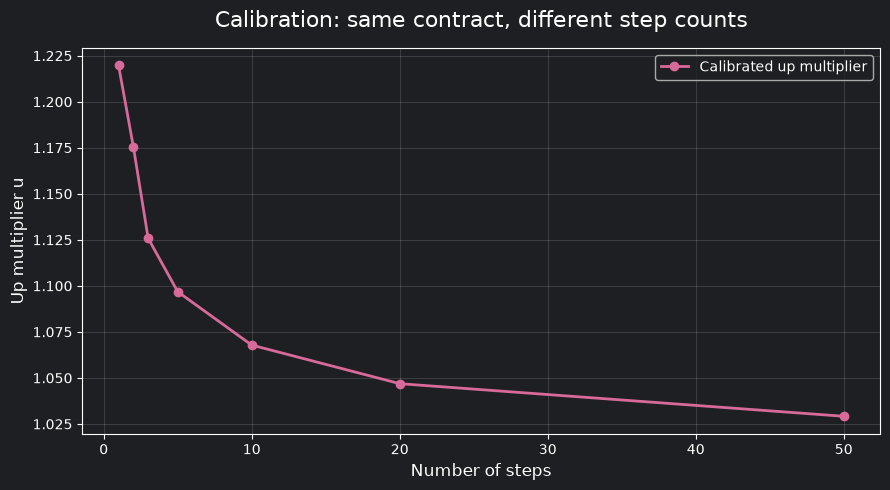

(<Figure size 900x500 with 1 Axes>,
 <Axes: title={'center': 'Calibration: same contract, different step counts'}, xlabel='Number of steps', ylabel='Up multiplier u'>)

In [21]:
S = 100.0
K = 100.0
r = 0.05
T = 1.0
sigma = 0.20

target_price = bsm_call(S, K, r, T, sigma)

steps_list = [1, 2, 3, 5, 10, 20, 50]
calibrated_up_steps = []

print(f"Target price: {target_price:.8f}")

for steps in steps_list:
    # Keep the annual interest rate fixed
    df = np.exp(-r * T / steps)

    u = calibrate(target_price, S, K, df, steps)
    calibrated_up_steps.append(u)

    tree_price = balanced_call_price(S, K, df, steps, u)

    print(
        f"Steps: {steps:2d} | u: {u:.6f} | "
        f"Tree price: {tree_price:.8f} | "
        f"Error: {tree_price - target_price:.2e}"
    )

    assert np.isclose(
        tree_price, target_price, rtol=1e-9, atol=1e-9
    )

my_plotter(
    steps_list,
    calibrated_up_steps,
    names=["Calibrated up multiplier"],
    layout={
        "title": "Calibration: same contract, different step counts",
        "x_label": "Number of steps",
        "y_label": "Up multiplier u",
        "colors": ["#D76A99"],
        "linewidth": 2,
        "marker": "o",
        "zero_line": False,
        "grid": True
    }
)

K: 80, u: 1.316991, target: 24.58883544, tree: 24.58883544
K: 85, u: 1.280375, target: 20.46928792, tree: 20.46928792
K: 90, u: 1.251113, target: 16.69944841, tree: 16.69944841
K: 95, u: 1.230615, target: 13.34646495, tree: 13.34646495
K: 100, u: 1.219728, target: 10.45058357, tree: 10.45058357
K: 105, u: 1.218652, target: 8.02135224, tree: 8.02135224
K: 110, u: 1.226995, target: 6.04008813, tree: 6.04008813
K: 115, u: 1.243912, target: 4.46657915, tree: 4.46657915
K: 120, u: 1.268280, target: 3.24747742, tree: 3.24747742


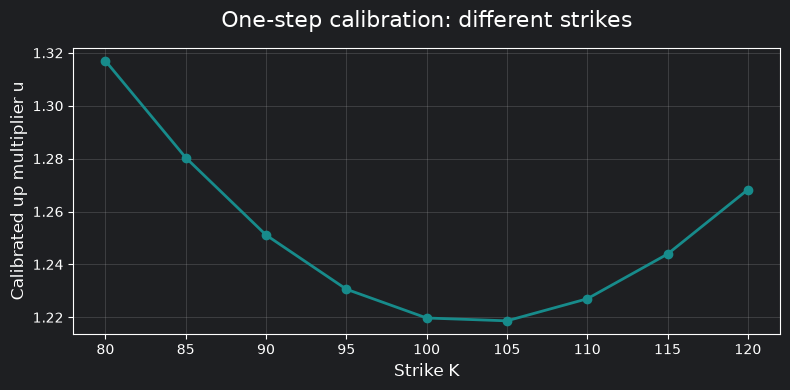

(<Figure size 800x400 with 1 Axes>,
 <Axes: title={'center': 'One-step calibration: different strikes'}, xlabel='Strike K', ylabel='Calibrated up multiplier u'>)

In [22]:
#One step trees, different strikes
strikes = np.arange(80, 125, 5)
up_strikes = []

steps = 1
df = np.exp(-r * T)

for strike in strikes:
    target_price = bsm_call(S, strike, r, T, sigma)

    u = calibrate(target_price, S, strike, df, steps)
    up_strikes.append(u)

    fitted_price = balanced_call_price(S, strike, df, steps, u)

    print(
        f"K: {strike}, u: {u:.6f}, "
        f"target: {target_price:.8f}, tree: {fitted_price:.8f}"
    )

    assert np.isclose(fitted_price, target_price, rtol=1e-9, atol=1e-9)

my_plotter(
    strikes,
    up_strikes,
    layout={
        "title": "One-step calibration: different strikes",
        "x_label": "Strike K",
        "y_label": "Calibrated up multiplier u",
        "figsize": (8, 4),
        "colors": ["#178B8B"],
        "marker": "o",
        "linewidth": 2,
        "grid": True,
        "zero_line": False
    }
)

T: 0.25, u: 1.093461, target: 4.61499713, tree: 4.61499713
T: 0.50, u: 1.141262, target: 6.88872858, tree: 6.88872858
T: 0.75, u: 1.182149, target: 8.77226826, tree: 8.77226826
T: 1.00, u: 1.219728, target: 10.45058357, tree: 10.45058357
T: 1.50, u: 1.289798, target: 13.44290481, tree: 13.44290481
T: 2.00, u: 1.356457, target: 16.12677972, tree: 16.12677972
T: 3.00, u: 1.486213, target: 20.92436095, tree: 20.92436095


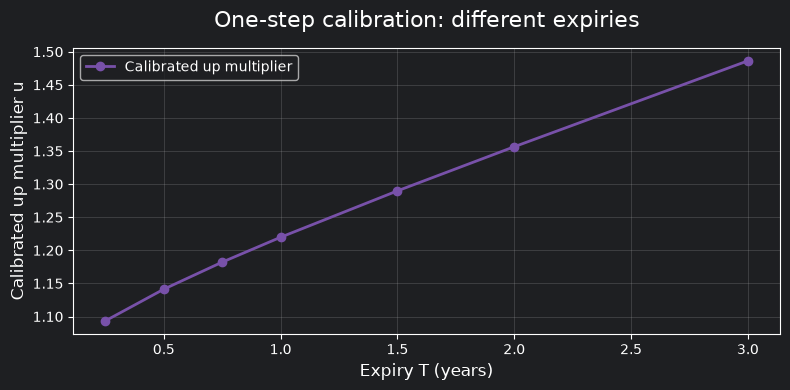

(<Figure size 800x400 with 1 Axes>,
 <Axes: title={'center': 'One-step calibration: different expiries'}, xlabel='Expiry T (years)', ylabel='Calibrated up multiplier u'>)

In [23]:
expiries = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
up_expiries = []

for expiry in expiries:
    df = np.exp(-r * expiry)

    target_price = bsm_call(S, K, r, expiry, sigma)

    u = calibrate(target_price, S, K, df, steps=1)
    up_expiries.append(u)

    fitted_price = balanced_call_price(S, K, df, 1, u)

    print(
        f"T: {expiry:.2f}, u: {u:.6f}, "
        f"target: {target_price:.8f}, tree: {fitted_price:.8f}"
    )

    assert np.isclose(
        fitted_price, target_price, rtol=1e-9, atol=1e-9
    )

my_plotter(
    expiries,
    up_expiries,
    names=["Calibrated up multiplier"],
    layout={
        "title": "One-step calibration: different expiries",
        "x_label": "Expiry T (years)",
        "y_label": "Calibrated up multiplier u",
        "figsize": (8, 4),
        "colors": ["#7851A9"],
        "linewidth": 2,
        "marker": "o",
        "grid": True,
        "zero_line": False
    }
)

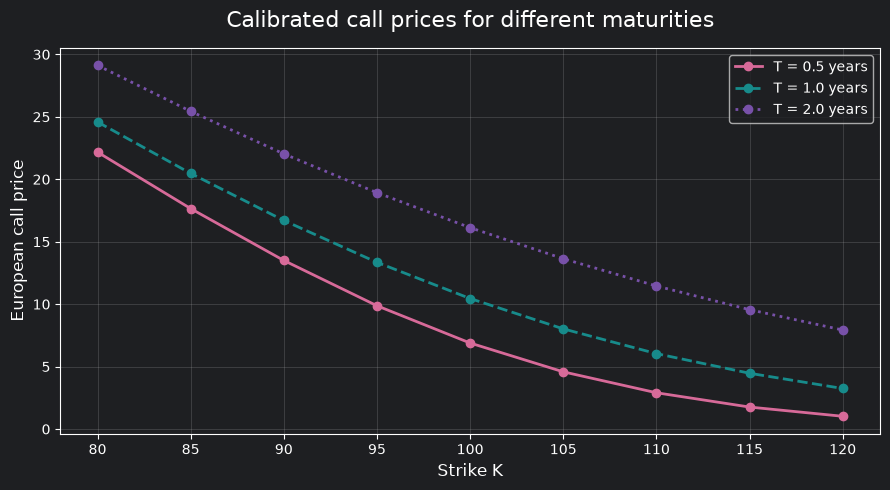

(<Figure size 900x500 with 1 Axes>,
 <Axes: title={'center': 'Calibrated call prices for different maturities'}, xlabel='Strike K', ylabel='European call price'>)

In [24]:
S = 100.0
r = 0.05
sigma = 0.20
steps = 1

strikes = np.arange(80, 125, 5)
maturities = [0.5, 1.0, 2.0]

prices_to_plot = []
names = []

for maturity in maturities:
    df = np.exp(-r * maturity / steps)
    prices = []

    for strike in strikes:
        target = bsm_call(S, strike, r, maturity, sigma)

        u = calibrate(target, S, strike, df, steps)

        fitted_price = balanced_call_price(
            S, strike, df, steps, u
        )

        assert np.isclose(
            fitted_price, target, rtol=1e-9, atol=1e-9
        )

        prices.append(fitted_price)

    prices_to_plot.append(prices)
    names.append(f"T = {maturity} years")

my_plotter(
    strikes,
    prices_to_plot,
    names=names,
    layout={
        "title": "Calibrated call prices for different maturities",
        "x_label": "Strike K",
        "y_label": "European call price",
        "figsize": (9, 5),
        "colors": ["#D76A99", "#178B8B", "#7851A9"],
        "styles": ["-", "--", ":"],
        "linewidth": 2,
        "marker": "o",
        "grid": True,
        "zero_line": False
    }
)